# 06: summary scoreboard

This notebook reads the numbers the other notebooks saved in `notebooks/results/` (run 01 to 05 first) and puts them side by side. Every comparison is at the **largest size** each notebook raced, because that's where a speed library has to earn its keep.

"vs sklearn" above 1 means faster than scikit-learn's default. For PCA the baseline is `PCA()` with its default solver.

In [1]:
import sys
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bench_utils import load_results, ENGINE_COLORS, machine_info

pd.set_option("display.float_format", "{:,.2f}".format)
%matplotlib inline

def at_largest(df, size_col):
    return df[df[size_col] == df[size_col].max()]

parts = []
knn, _ = load_results("knn")
parts.append(at_largest(knn, "train rows").assign(algorithm="KNN (predict)", measure="predict s"))
km, _ = load_results("kmeans")
parts.append(at_largest(km, "rows").assign(algorithm="k-means (per iteration)", measure="s per iteration"))
ridge, _ = load_results("ridge")
parts.append(at_largest(ridge, "rows").assign(algorithm="Ridge (fit)", measure="fit s"))
pca, _ = load_results("pca")
pca = pca.rename(columns={"vs sklearn default": "vs sklearn"})
pca["engine"] = pca["engine"].replace({"sklearn (svd_solver=auto)": "sklearn"})
parts.append(at_largest(pca, "rows").assign(algorithm="PCA (fit)", measure="fit s"))
tree, _ = load_results("tree")
parts.append(at_largest(tree, "depth").assign(algorithm="Decision tree (fit)", measure="fit s"))

board = pd.concat(parts, ignore_index=True)
board["seconds"] = [row[row["measure"]] for _, row in board.iterrows()]
board = board[["algorithm", "engine", "seconds", "vs sklearn"]]
board.pivot(index="algorithm", columns="engine", values="vs sklearn").reindex(
    columns=[c for c in ["sklearn", "sklearn (svd_solver=full)", "sklearn (svd_solver=randomized)",
                         "autoalgo-numpy", "autoalgo-mlx", "autoalgo-rust", "autoalgo-rust-blas"]
             if c in board["engine"].unique()])

engine,sklearn,sklearn (svd_solver=full),sklearn (svd_solver=randomized),autoalgo-numpy,autoalgo-mlx,autoalgo-rust,autoalgo-rust-blas
algorithm,,,,,,,
Decision tree (fit),1.00,NaN,NaN,0.33,NaN,2.30,NaN
KNN (predict),1.00,NaN,NaN,0.12,0.89,0.61,3.02
PCA (fit),1.00,0.02,0.06,0.56,0.55,NaN,NaN
Ridge (fit),1.00,NaN,NaN,1.19,1.11,NaN,NaN
k-means (per iteration),1.00,NaN,NaN,0.09,0.37,1.68,NaN


## Speed vs scikit-learn, by algorithm

Each bar is one autoalgo engine. The gray line at 1× is scikit-learn; bars to the right are faster. The x axis is logarithmic, so 0.5× (twice as slow) and 2× (twice as fast) sit the same distance from the line.

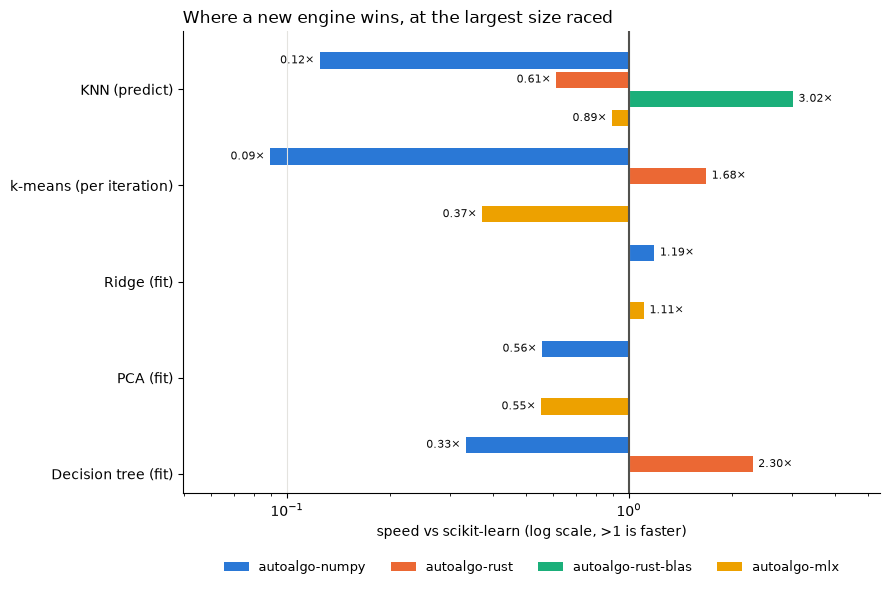

In [2]:
engines = [e for e in ENGINE_COLORS if e in board["engine"].unique()]
algos = list(dict.fromkeys(board["algorithm"]))
fig, ax = plt.subplots(figsize=(9, 6))
bar_h = 0.8 / len(engines)
for j, engine in enumerate(engines):
    for i, algo in enumerate(algos):
        row = board[(board["algorithm"] == algo) & (board["engine"] == engine)]
        if row.empty:
            continue
        v = float(row["vs sklearn"].iloc[0])
        y = i + (j - (len(engines) - 1) / 2) * bar_h
        lo, hi = min(v, 1.0), max(v, 1.0)  # each bar grows out from the 1x line
        ax.barh(y, hi - lo, height=bar_h - 0.03, left=lo, color=ENGINE_COLORS[engine],
                label=engine if engine not in ax.get_legend_handles_labels()[1] else None)
        ax.annotate(f"{v:.2f}×", (v, y), xytext=(4 if v >= 1 else -4, 0), textcoords="offset points",
                    ha="left" if v >= 1 else "right", va="center", fontsize=8, color="#0b0b0b")
ax.set_xscale("log")
ax.axvline(1, color="#52514e", linewidth=1.5)
ax.set_yticks(range(len(algos)), algos)
ax.invert_yaxis()
ax.set_xlabel("speed vs scikit-learn (log scale, >1 is faster)")
ax.set_title("Where a new engine wins, at the largest size raced", loc="left", fontsize=12)
ax.grid(True, axis="x", color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
seen = dict(zip(labels, handles))
ax.legend(seen.values(), seen.keys(), frameon=False, fontsize=9, loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=len(seen))
vals = board.loc[board["engine"].isin(engines), "vs sklearn"]
ax.set_xlim(vals.min() / 1.8, vals.max() * 1.8)
plt.show()

## Single-row latency (KNN)

The batch numbers above hide the case a robot or a live API cares about: one prediction at a time.

In [3]:
_, payload = load_results("knn")
pd.DataFrame(payload["notes"]["latency"])[["train rows", "engine", "median µs", "vs sklearn"]]

,train rows,engine,median µs,vs sklearn
0,10000,sklearn,514.54,1.00
1,10000,autoalgo-numpy,93.65,5.49
2,10000,autoalgo-rust,48.50,10.61
3,10000,autoalgo-rust-blas,36.79,13.99
4,10000,autoalgo-mlx,395.60,1.30
5,200000,sklearn,"2,437.85",1.00
6,200000,autoalgo-numpy,"1,404.75",1.74
7,200000,autoalgo-rust,873.21,2.79
8,200000,autoalgo-rust-blas,887.37,2.75
9,200000,autoalgo-mlx,989.21,2.46


## What the five races say

*Numbers quoted here are from the run committed with this repo (Apple M4, 24 GB). Re-running will shift them a little; the pattern should hold.*

**1. Python on top of NumPy loses almost everywhere.** The NumPy engines were 6 to 12 times slower than scikit-learn on KNN and k-means, and up to 3 times slower on deep trees. Each time, the cause was a memory-bound step (picking the k smallest, summing rows per cluster, one Python call per tree node) that scikit-learn runs in compiled code. The one NumPy win, Ridge, came from a smarter formulation, not a faster engine.

**2. The GPU (MLX) roughly ties at best.** About 1× on KNN, 0.4 to 0.5× on k-means, 1.1 to 1.3× on Ridge, and slower when Ridge has many features. Pure Python on the GPU still has to write big intermediate matrices to memory and read them back.

**3. Compiled Rust wins clearly in 3 of 5 algorithms:**

| Algorithm | Rust vs scikit-learn | What made it win |
|---|---|---|
| KNN, batch | **2.5 to 3.8× faster** | Rust controls the loop; Accelerate's matrix units do the distances |
| KNN, one row | **10 to 14× faster** on 10k rows, about 2.8× on 200k | no per-call Python overhead |
| k-means | **1.7 to 1.9× faster** | assign and sum in one pass, every core |
| Decision tree, fit | **2.3 to 3.6× faster** | histogram algorithm plus parallel counting (and slightly higher accuracy) |
| Decision tree, predict | **6 to 8× faster** | compares raw values, no binning, every core |

**4. Two algorithms had no headroom.** Ridge and PCA are one big matrix multiply, which scikit-learn already hands to the same hardware. autoalgo's Ridge is only 1.1 to 1.3× faster. In exchange it's 40 to 400 times *more accurate* on big data, because it centers in chunks and sums in 64-bit. For PCA, scikit-learn's default was **1.5 to 1.9× faster than autoalgo**.

**5. The biggest speed difference wasn't the engine at all.** In PCA, the same library on the same data took 0.14 seconds or 5.8 seconds depending on one setting (`svd_solver="auto"` vs `"full"`), a **43× gap**. The best engine win anywhere in these races was under 4× on batch work. Picking the right algorithm and settings mattered more than making any one algorithm faster.

**6. Speed came with correctness work.** Getting each engine to win *and* match scikit-learn took real debugging:
- k-means results that varied from run to run
- a Ridge shortcut that quietly lost precision
- tree prediction spending 98% of its time binning

That work multiplies across every algorithm you add.

## What this means for the two paths

**Path A: autoalgo as an alternative to scikit-learn.** The races say it's *possible* algorithm by algorithm. Expect roughly 2 to 4× on batch work and 10×+ on single predictions, but only with compiled code, only on some algorithms, and only after careful engineering and testing for each one. scikit-learn has hundreds of estimators; matching it broadly is years of work, mostly in Rust.

**Path B: autoalgo as a navigator for scikit-learn.** The single biggest measured win (43×) came from choosing the right solver, which is exactly what a navigator does. It's pure Python and works for every scikit-learn algorithm on day one. Its value grows with the size of scikit-learn's catalog instead of fighting it.

**A hybrid is what the evidence points to.** Build the navigator as the product: it recommends an algorithm, a solver and settings for the user's data and hardware, then runs scikit-learn. Keep the measured winners (Rust KNN, k-means and trees) as optional "turbo" engines it can switch to when they're actually faster on that machine. The Rust stays small, contained and optional.

In [4]:
pd.Series(machine_info(), name="machine these numbers came from")

chip                                  Apple M4
cores             4 performance + 6 efficiency
ram_gb                                      24
os         macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                  3.13.5
numpy                       2.5.4 (accelerate)
sklearn                                  1.9.1
mlx                                     0.32.4
Name: machine these numbers came from, dtype: object